# Hürlimann: how formula (2.1) works

Hürlimann (2009), section 2 defines the **loss ratio** for development period $k$:

$$m_k = \frac{E\left[\sum_{i=1}^{n-k+1} S_{ik}\right]}{\sum_{i=1}^{n-k+1} V_i},\qquad k = 1,\dots,n \tag{2.1}$$

where $S_{ik}$ is the incremental paid claim of origin period $i$ in development period $k$, and $V_i$ is the premium (exposure) of origin period $i$.

Reading it for a given $k$:

* **Numerator:** column $k$ of the incremental triangle, but only origin periods $i = 1,\dots,n-k+1$, i.e. the cells that have actually been observed. In practice the expectation is replaced by the observed sum.
* **Denominator:** the premiums of **exactly those same origin periods**. Origin periods that have not reached development period $k$ are left out of both.

So $m_k$ is a premium-weighted average of the incremental loss ratios $S_{ik}/V_i$ in column $k$. As $k$ grows, fewer origin periods contribute.

**The triangle below is synthetic** (invented for illustration, not from the paper or an exam): $n = 10$, premiums growing ~5% a year, a made-up payout pattern, and fixed-seed noise.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

n = 10
rng = np.random.default_rng(7)

# Synthetic inputs (assumed, for illustration only)
V = np.round(1000 * 1.05 ** np.arange(n))                   # premium V_i
m_true = np.array([.18, .20, .14, .09, .06, .04, .03, .02, .015, .01])  # "true" loss ratios
S_full = np.round(V[:, None] * m_true[None, :] * rng.normal(1, 0.08, (n, n)))

# Keep only the observed upper-left triangle: S_ik observed iff i + k <= n + 1 (1-based)
i_idx, k_idx = np.indices((n, n)) + 1
observed = i_idx + k_idx <= n + 1
S = np.where(observed, S_full, np.nan)

pd.DataFrame(S, index=pd.Index(range(1, n + 1), name='i'),
             columns=pd.Index(range(1, n + 1), name='k')).assign(V=V).fillna('')

k,1,2,3,4,5,6,7,8,9,10,V
i,,,,,,,,,,,
1,180.0,205.0,137.0,84.0,58.0,37.0,30.0,22.0,14.0,10.0,1000.0
2,196.0,216.0,148.0,87.0,63.0,44.0,28.0,20.0,13.0,,1050.0
3,169.0,216.0,139.0,101.0,67.0,43.0,26.0,21.0,,,1102.0
4,183.0,223.0,149.0,97.0,75.0,43.0,35.0,,,,1158.0
5,221.0,244.0,154.0,110.0,81.0,43.0,,,,,1216.0
6,244.0,231.0,180.0,120.0,75.0,,,,,,1276.0
7,245.0,258.0,190.0,109.0,,,,,,,1340.0
8,266.0,237.0,190.0,,,,,,,,1407.0
9,257.0,288.0,,,,,,,,,1477.0


## Computing (2.1) directly

For each $k$, take rows $1,\dots,n-k+1$ (the observed cells in column $k$).

In [2]:
def m_k(k):
    rows = slice(0, n - k + 1)               # i = 1..n-k+1
    return S[rows, k - 1].sum() / V[rows].sum()

m = np.array([m_k(k) for k in range(1, n + 1)])
pd.DataFrame({'k': range(1, n + 1),
              'rows used': [f'1..{n-k+1}' for k in range(1, n+1)],
              'numerator  sum S_ik': [S[:n-k+1, k-1].sum() for k in range(1, n+1)],
              'denominator  sum V_i': [V[:n-k+1].sum() for k in range(1, n+1)],
              'm_k': m.round(4),
              'assumed true m_k': m_true}).set_index('k')

,rows used,numerator sum S_ik,denominator sum V_i,m_k,assumed true m_k
k,,,,,
1,1..10,2240.0,12577.0,0.1781,0.180
2,1..9,2118.0,11026.0,0.1921,0.200
3,1..8,1287.0,9549.0,0.1348,0.140
4,1..7,708.0,8142.0,0.0870,0.090
5,1..6,419.0,6802.0,0.0616,0.060
6,1..5,210.0,5526.0,0.0380,0.040
7,1..4,119.0,4310.0,0.0276,0.030
8,1..3,63.0,3152.0,0.0200,0.020
9,1..2,27.0,2050.0,0.0132,0.015


## Picture: which cells go into $m_k$

For a chosen $k$:

* **Blue** cells are the numerator, $S_{ik}$ for $i = 1,\dots,n-k+1$.
* The **orange** premium column entries are the denominator, $V_i$ for the same rows.
* The **shaded band** marks the rows $1..n-k+1$ that contribute. Cells in other columns are greyed out, and the blank lower-right is the unobserved part of the triangle.

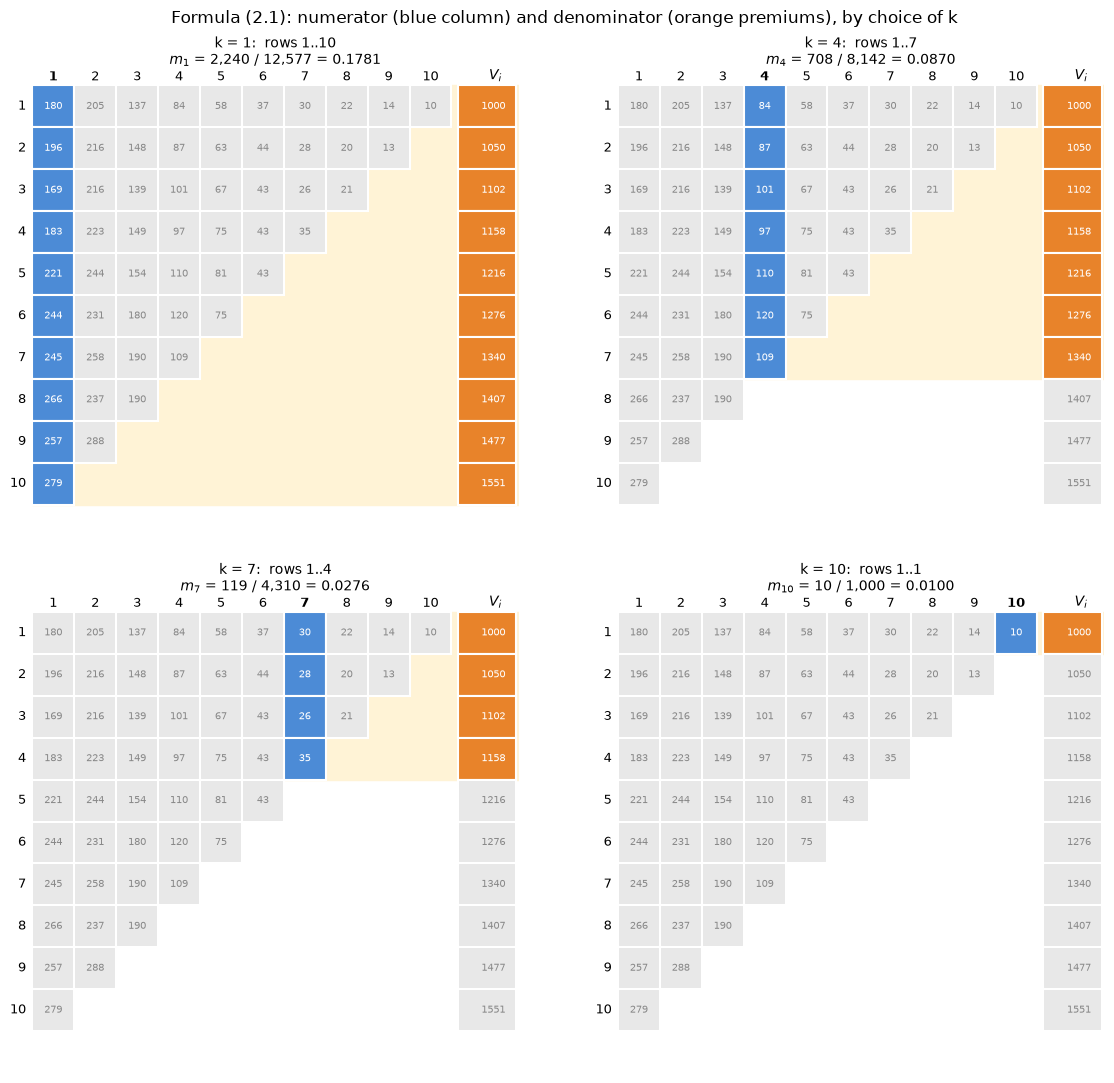

In [3]:
def draw(k, ax, annotate=True):
    last = n - k + 1                                  # last contributing origin period
    ax.set_xlim(0, n + 1.6); ax.set_ylim(n + 1, -0.3)
    ax.set_aspect('equal'); ax.axis('off')

    # headers
    for kk in range(1, n + 1):
        ax.text(kk - .5, -.05, kk, ha='center', va='bottom', fontsize=9,
                fontweight='bold' if kk == k else 'normal')
    ax.text(n + 1.05, -.05, '$V_i$', ha='center', va='bottom', fontsize=10, fontweight='bold')

    # row band for contributing rows
    ax.add_patch(Rectangle((0, 0), n + 1.6, last, color='#fff3d6', zorder=0))

    for i in range(1, n + 1):
        ax.text(-.15, i - .5, i, ha='right', va='center', fontsize=9)
        used = i <= last
        for kk in range(1, n + 1):
            if not observed[i-1, kk-1]:
                continue
            hit = (kk == k)                           # numerator cell
            fc = '#4c8bd6' if hit else ('#e8e8e8')
            ax.add_patch(Rectangle((kk - 1, i - 1), 1, 1, fc=fc, ec='white', lw=1.5, zorder=1))
            if annotate:
                ax.text(kk - .5, i - .5, f'{S[i-1, kk-1]:.0f}', ha='center', va='center',
                        fontsize=7, color='white' if hit else '#888')
        # premium cell
        ax.add_patch(Rectangle((n + .15, i - 1), 1.7 - .3, 1, fc='#e8832a' if used else '#e8e8e8',
                               ec='white', lw=1.5, zorder=1))
        ax.text(n + 1, i - .5, f'{V[i-1]:.0f}', ha='center', va='center', fontsize=7,
                color='white' if used else '#888')

    num, den = S[:last, k-1].sum(), V[:last].sum()
    ax.set_title(f'k = {k}:  rows 1..{last}\n'
                 f'$m_{{{k}}}$ = {num:,.0f} / {den:,.0f} = {num/den:.4f}', fontsize=10)

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, k in zip(axes.ravel(), [1, 4, 7, 10]):
    draw(k, ax)
fig.suptitle('Formula (2.1): numerator (blue column) and denominator (orange premiums), by choice of k',
             fontsize=12)
plt.tight_layout(); plt.show()

### Reading the pictures

* **k = 1:** the whole first column is used (all 10 origin periods), against all 10 premiums.
* **k = 4:** only origin periods 1..7 have reached development period 4. Rows 8–10 are excluded from numerator **and** denominator, so their premiums do not dilute $m_4$.
* **k = 7:** only 4 origin periods, so the estimate rests on little data.
* **k = 10:** a single cell, $S_{1,10}$, divided by $V_1$. $m_{10}$ is just that one cell's loss ratio.

Why the denominator must match: if all 10 premiums were used for $k=10$, $m_{10}$ would be biased downward by a factor of about $V_1 / \sum V_i$, because origin periods 2–10 have no $S_{i,10}$ yet.

### All ten values of $k$ at a glance (cell values hidden)

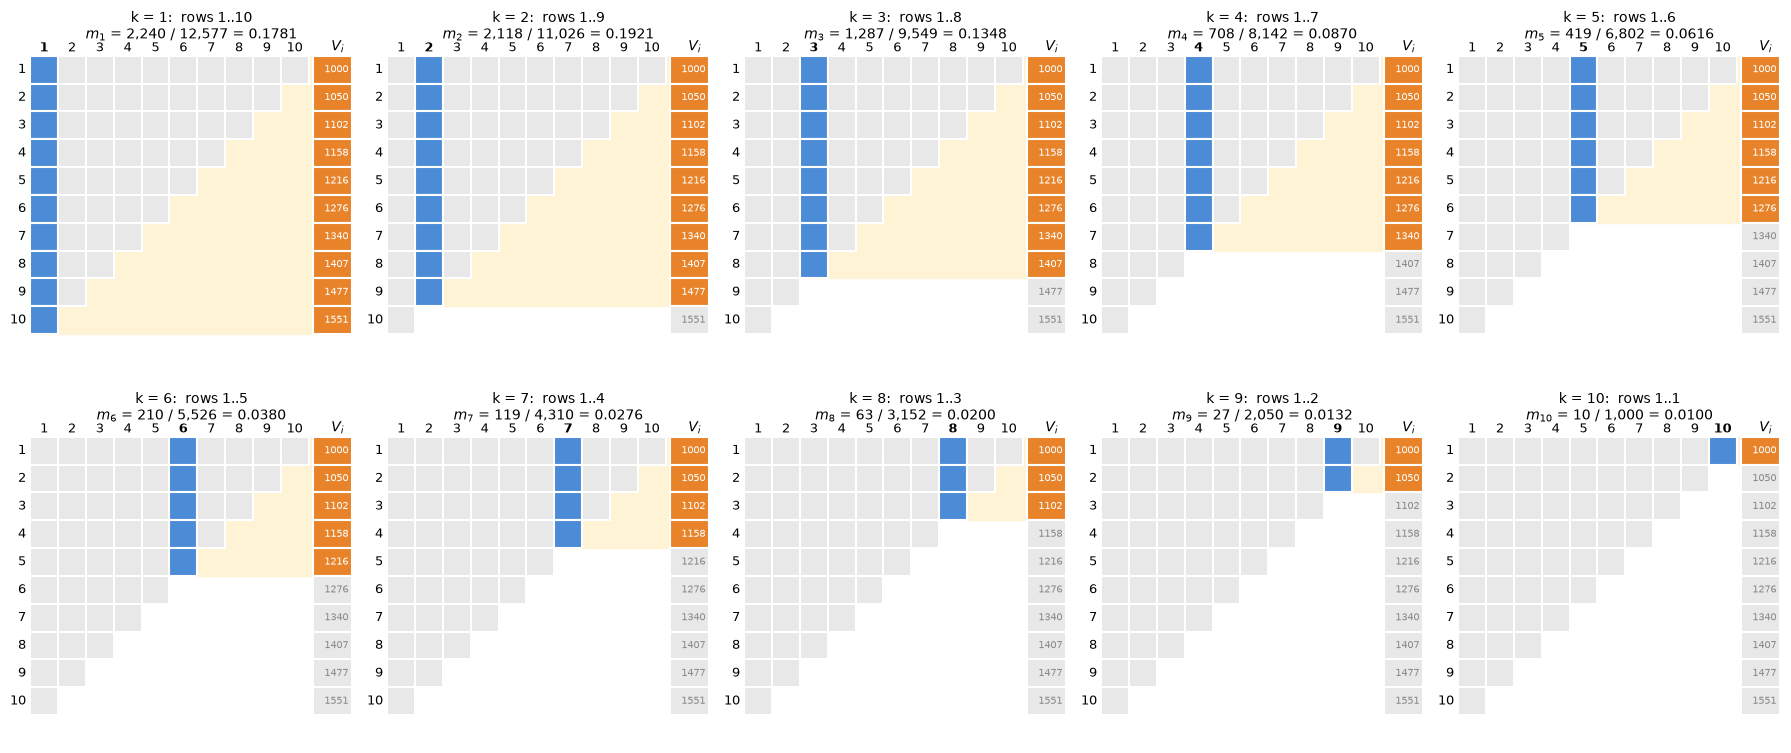

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, k in zip(axes.ravel(), range(1, n + 1)):
    draw(k, ax, annotate=False)
plt.tight_layout(); plt.show()

### Putting the $m_k$ to use

Summing gives the burning-cost loss ratio $\sum_k m_k$ used in (2.2), and the payout factors in (2.3)–(2.4) are built from partial sums of the same $m_k$. Quick check of the estimates against the pattern the data was generated from:

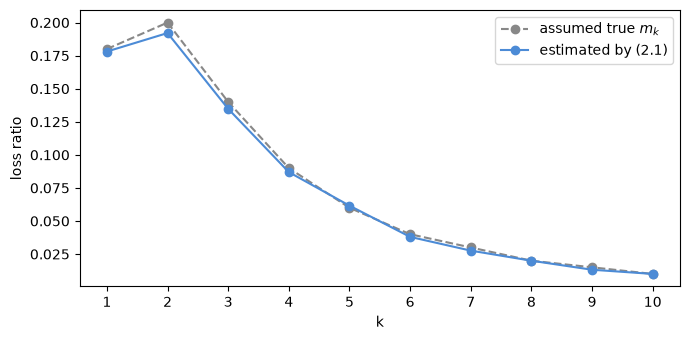

sum of m_k (loss ratio over all periods): 0.7623  true: 0.785


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, n + 1), m_true, 'o--', label='assumed true $m_k$', color='#888')
ax.plot(range(1, n + 1), m, 'o-', label='estimated by (2.1)', color='#4c8bd6')
ax.set_xlabel('k'); ax.set_ylabel('loss ratio'); ax.legend(); ax.set_xticks(range(1, n + 1))
plt.tight_layout(); plt.show()
print('sum of m_k (loss ratio over all periods):', m.sum().round(4), ' true:', m_true.sum())